# 1. Load Dataset

In [2]:
import sys
from pathlib import Path

import pandas as pd

repo_root = Path.cwd()
if repo_root.name == "notebooks":
    repo_root = repo_root.parent

if not (repo_root / "src").is_dir():
    raise RuntimeError("Buka notebook dari root repo atau folder notebooks.")

sys.path.insert(0, str(repo_root))

train_raw = pd.read_csv(repo_root / "data" / "train.csv")
test_raw = pd.read_csv(repo_root / "data" / "test.csv")

print("Train mentah", train_raw.shape)
print("Test mentah", test_raw.shape)

Train mentah (27373, 19)
Test mentah (6844, 18)


# 2. Preprocessing

In [3]:
from src.processing.cleaning import split_data
from src.processing.pipeline import runPreprocessing

FEATURE_COUNT = None
PCA_COMPONENTS = None
OVERSAMPLE = False

X_train, X_val, y_train, y_val, X_test, id_test = split_data(train_raw, test_raw)

X_train_ready, y_train_ready, prep = runPreprocessing(
    X_train,
    y_train,
    fit=True,
    featureCount=FEATURE_COUNT,
    components=PCA_COMPONENTS,
    oversample=OVERSAMPLE,
    name="train",
)

X_val_ready, y_val_ready, _ = runPreprocessing(
    X_val, y_val, state=prep, name="validation"
)
X_test_ready, _, _ = runPreprocessing(X_test, state=prep, name="test")

assert X_train_ready.columns.equals(X_val_ready.columns)
assert X_train_ready.columns.equals(X_test_ready.columns)

print("Train", X_train_ready.shape)
print("Validasi", X_val_ready.shape)
print("Test", X_test_ready.shape)

Train (21857, 30)
Validasi (5475, 30)
Test (6844, 30)


# 3. Tuning k dan perbandingan scikit-learn

In [4]:
import numpy as np
from sklearn.neighbors import KNeighborsClassifier

from src.evaluation.metrics import evaluateMetrics

K_VALUES = list(range(2, 34))
METRIC = "f1Score"

train_array = X_train_ready.to_numpy(dtype=float)
val_array = X_val_ready.to_numpy(dtype=float)
train_labels = y_train_ready.to_numpy(dtype=int)
val_labels = y_val_ready.to_numpy(dtype=int)


def nearest_labels(train, labels, queries, max_k, batch_size=16):
    train_columns = np.ascontiguousarray(train.T)
    result = np.empty((len(queries), max_k), dtype=labels.dtype)

    for start in range(0, len(queries), batch_size):
        batch = queries[start:start + batch_size]
        distances = np.zeros((len(batch), len(train)))
        delta = np.empty_like(distances)

        for query_col, train_col in zip(batch.T, train_columns):
            np.subtract(query_col[:, None], train_col, out=delta)
            np.square(delta, out=delta)
            np.add(distances, delta, out=distances)

        np.sqrt(distances, out=distances)

        # Untuk jarak yang sama, pertahankan urutan baris train.
        indices = np.argsort(distances, axis=1, kind="stable")[:, :max_k]
        result[start:start + len(batch)] = labels[indices]

    return result


neighbors = nearest_labels(train_array, train_labels, val_array, max(K_VALUES))
results = []

for k in K_VALUES:
    custom_pred = (neighbors[:, :k].sum(axis=1) > k / 2).astype(int)

    baseline = KNeighborsClassifier(
        n_neighbors=k,
        weights="uniform",
        metric="euclidean",
        algorithm="brute",
    ).fit(train_array, train_labels)
    baseline_pred = baseline.predict(val_array)

    for model_name, pred in (
        ("KNN from scratch", custom_pred),
        ("KNN scikit-learn", baseline_pred),
    ):
        results.append({
            "model": model_name,
            "k": k,
            **evaluateMetrics(pred, val_labels),
        })

scores = pd.DataFrame(results)
custom_scores = scores.loc[scores["model"] == "KNN from scratch"]
best = custom_scores.loc[custom_scores[METRIC].idxmax()]
BEST_K = int(best["k"])

print(f"Validasi memakai {len(val_labels)} baris.")
print(f"KNN from scratch terpilih: k={BEST_K}, {METRIC}={best[METRIC]:.4f}")
scores.round(4)

Validasi memakai 5475 baris.
KNN from scratch terpilih: k=5, f1Score=0.7424


,model,k,accuracy,precision,recall,f1Score,balancedAccuracy
0,KNN from scratch,2,0.8241,0.8112,0.6037,0.6922,0.7676
1,KNN scikit-learn,2,0.8241,0.8112,0.6037,0.6922,0.7676
2,KNN from scratch,3,0.8274,0.7397,0.7302,0.7349,0.8025
3,KNN scikit-learn,3,0.8274,0.7397,0.7302,0.7349,0.8025
4,KNN from scratch,4,0.8338,0.8113,0.6421,0.7169,0.7847
...,...,...,...,...,...,...,...
59,KNN scikit-learn,31,0.8258,0.7658,0.6745,0.7172,0.7870
60,KNN from scratch,32,0.8268,0.7794,0.6577,0.7134,0.7835
61,KNN scikit-learn,32,0.8268,0.7794,0.6577,0.7134,0.7835
62,KNN from scratch,33,0.8296,0.7733,0.6789,0.7231,0.7910


# 4. Skor validasi

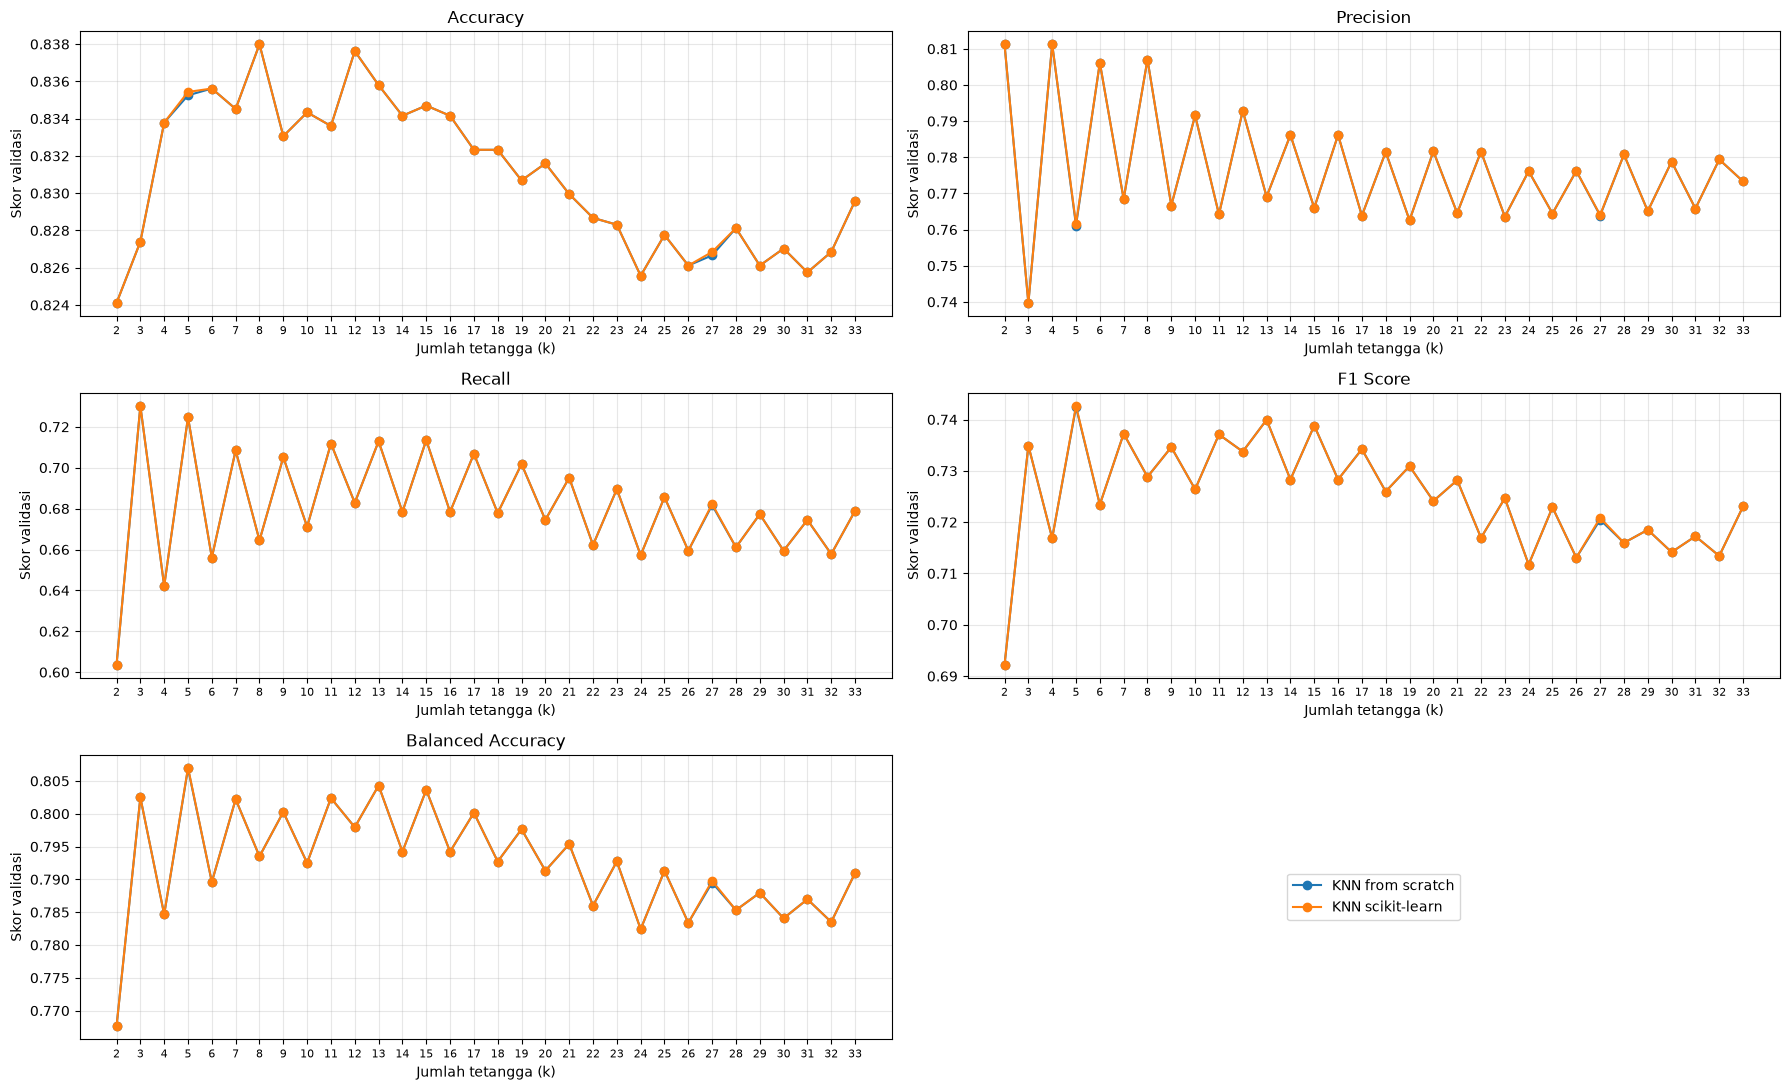

In [5]:
import matplotlib.pyplot as plt

metrics = {
    "accuracy": "Accuracy",
    "precision": "Precision",
    "recall": "Recall",
    "f1Score": "F1 Score",
    "balancedAccuracy": "Balanced Accuracy",
}

k_ticks = sorted(scores["k"].unique())
model_groups = scores.sort_values("k").groupby("model", sort=False)

fig, axes = plt.subplots(3, 2, figsize=(18, 11))

for ax, (metric, title) in zip(axes.flat, metrics.items()):
    for model_name, group in model_groups:
        ax.plot(group["k"], group[metric], marker="o", label=model_name)

    ax.set_title(title)
    ax.set_xlabel("Jumlah tetangga (k)")
    ax.set_ylabel("Skor validasi")
    ax.set_xticks(k_ticks)
    ax.tick_params(axis="x", labelsize=8)
    ax.grid(alpha=0.3)

handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center")
axes.flat[-1].axis("off")

fig.tight_layout()
plt.show()